Set the resolved dataset location and project seed for the audit.

In [1]:
from pathlib import Path

DATASET_ROOT = Path(r"C:\Users\User\Downloads\archive\real_vs_fake\real-vs-fake").resolve()
SEED = 42
print("DATASET_ROOT:", DATASET_ROOT)

DATASET_ROOT: C:\Users\User\Downloads\archive\real_vs_fake\real-vs-fake


Verify the required train/valid/test and real/fake directory layout and load project dependencies.

In [2]:
import random
import sys

import pandas as pd

SPLITS = ("train", "valid", "test")
CLASSES = ("real", "fake")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SPLIT_DIRS = {split: DATASET_ROOT / split for split in SPLITS}
print("Resolved split paths:")
for split, split_path in SPLIT_DIRS.items():
    print(f"{split}: {split_path.resolve()}")

missing = [
    DATASET_ROOT / split / class_name
    for split in SPLITS
    for class_name in CLASSES
    if not (DATASET_ROOT / split / class_name).is_dir()
]
if missing:
    raise FileNotFoundError(
        "Dataset layout must be {train,valid,test}/{real,fake}; missing: "
        + ", ".join(str(path) for path in missing)
    )

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src" / "datasets.py").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Could not locate project src/datasets.py")
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Resolved split paths:
train: C:\Users\User\Downloads\archive\real_vs_fake\real-vs-fake\train
valid: C:\Users\User\Downloads\archive\real_vs_fake\real-vs-fake\valid
test: C:\Users\User\Downloads\archive\real_vs_fake\real-vs-fake\test
Project root: C:\Users\User\Deepfake-Blockchain-Project


Count every supported image in each split/class and report the class balance.

In [3]:
IMAGE_PATHS = {
    split: {
        class_name: sorted(
            path for path in (SPLIT_DIRS[split] / class_name).rglob("*")
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        )
        for class_name in CLASSES
    }
    for split in SPLITS
}
count_rows = []
for split in SPLITS:
    class_counts = {class_name: len(IMAGE_PATHS[split][class_name]) for class_name in CLASSES}
    total = sum(class_counts.values())
    for class_name, count in class_counts.items():
        count_rows.append(
            {"split": split, "class": class_name, "images": count,
             "balance_percent": (100 * count / total) if total else 0.0}
        )
counts_df = pd.DataFrame(count_rows)
display(counts_df)
print("Total images per split:")
print(counts_df.groupby("split")["images"].sum().to_string())

,split,class,images,balance_percent
0,train,real,50000,50.0
1,train,fake,50000,50.0
2,valid,real,10000,50.0
3,valid,fake,10000,50.0
4,test,real,10000,50.0
5,test,fake,10000,50.0


Total images per split:
split
test      20000
train    100000
valid     20000


Inspect up to 2,000 seeded images per split for readability, dimensions, color mode, and file size.

In [4]:
from PIL import Image, UnidentifiedImageError

integrity_rows = []
unreadable_files = []
for split in SPLITS:
    all_paths = [path for class_name in CLASSES for path in IMAGE_PATHS[split][class_name]]
    sample = random.Random(SEED).sample(all_paths, min(2000, len(all_paths)))
    for path in sample:
        file_size = path.stat().st_size
        try:
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                integrity_rows.append(
                    {"split": split, "path": str(path.resolve()), "size": image.size,
                     "mode": image.mode, "file_size_bytes": file_size}
                )
        except (OSError, UnidentifiedImageError, ValueError) as error:
            unreadable_files.append({"split": split, "path": str(path.resolve()), "error": str(error)})

integrity_df = pd.DataFrame(integrity_rows)
non_rgb_df = integrity_df.loc[integrity_df["mode"] != "RGB", ["split", "path", "mode"]]
print(f"Unreadable sampled files: {len(unreadable_files)}")
if unreadable_files:
    display(pd.DataFrame(unreadable_files))
print(f"Non-RGB sampled files: {len(non_rgb_df)}")
if not non_rgb_df.empty:
    display(non_rgb_df)
print("Image size value counts by split:")
size_counts = integrity_df.groupby(["split", "size"], sort=True).size().rename("images").reset_index()
display(size_counts)
print("Sampled file-size summary (bytes):")
display(integrity_df.groupby("split")["file_size_bytes"].describe())

Unreadable sampled files: 0
Non-RGB sampled files: 0
Image size value counts by split:


,split,size,images
0,test,"(256, 256)",2000
1,train,"(256, 256)",2000
2,valid,"(256, 256)",2000


Sampled file-size summary (bytes):


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,2000.0,28686.7485,3943.140189,16755.0,25890.25,28371.5,31155.0,45090.0
train,2000.0,28680.6260,3940.568376,16346.0,25720.50,28343.5,31221.5,43870.0
valid,2000.0,28662.9605,3927.479314,13921.0,26032.25,28237.5,30954.0,51268.0


Check whether any exact filename is present in more than one dataset split.

In [5]:
filename_splits = {}
for split in SPLITS:
    for class_name in CLASSES:
        for path in IMAGE_PATHS[split][class_name]:
            filename_splits.setdefault(path.name, set()).add(split)
duplicate_filenames = {
    filename: sorted(split_names)
    for filename, split_names in filename_splits.items()
    if len(split_names) > 1
}
print("Cross-split duplicate filenames:", len(duplicate_filenames))
if duplicate_filenames:
    display(pd.DataFrame(
        [{"filename": filename, "splits": ", ".join(split_names)}
         for filename, split_names in sorted(duplicate_filenames.items())]
    ))

Cross-split duplicate filenames: 0


Compare MD5 hashes of up to 500 seeded random images per split for cross-split duplicate content.

In [6]:
import hashlib

hashes_by_split = {}
for split in SPLITS:
    all_paths = [path for class_name in CLASSES for path in IMAGE_PATHS[split][class_name]]
    sample = random.Random(SEED).sample(all_paths, min(500, len(all_paths)))
    split_hashes = {}
    for path in sample:
        digest = hashlib.md5()
        with path.open("rb") as image_file:
            for chunk in iter(lambda: image_file.read(1024 * 1024), b""):
                digest.update(chunk)
        split_hashes.setdefault(digest.hexdigest(), []).append(path)
    hashes_by_split[split] = split_hashes
    print(f"{split}: hashed {len(sample)} of {len(all_paths)} images")

cross_split_hash_matches = []
for index, first_split in enumerate(SPLITS):
    for second_split in SPLITS[index + 1:]:
        shared_hashes = set(hashes_by_split[first_split]) & set(hashes_by_split[second_split])
        for digest in sorted(shared_hashes):
            cross_split_hash_matches.append(
                {"md5": digest, "first_split": first_split,
                 "first_path": str(hashes_by_split[first_split][digest][0].resolve()),
                 "second_split": second_split,
                 "second_path": str(hashes_by_split[second_split][digest][0].resolve())}
            )
print("Cross-split duplicate hashes in sampled images:", len(cross_split_hash_matches))
if cross_split_hash_matches:
    display(pd.DataFrame(cross_split_hash_matches))

train: hashed 500 of 100000 images
valid: hashed 500 of 20000 images
test: hashed 500 of 20000 images
Cross-split duplicate hashes in sampled images: 0


Display a fixed-seed 6-by-3 sample grid with three real rows above three fake rows.

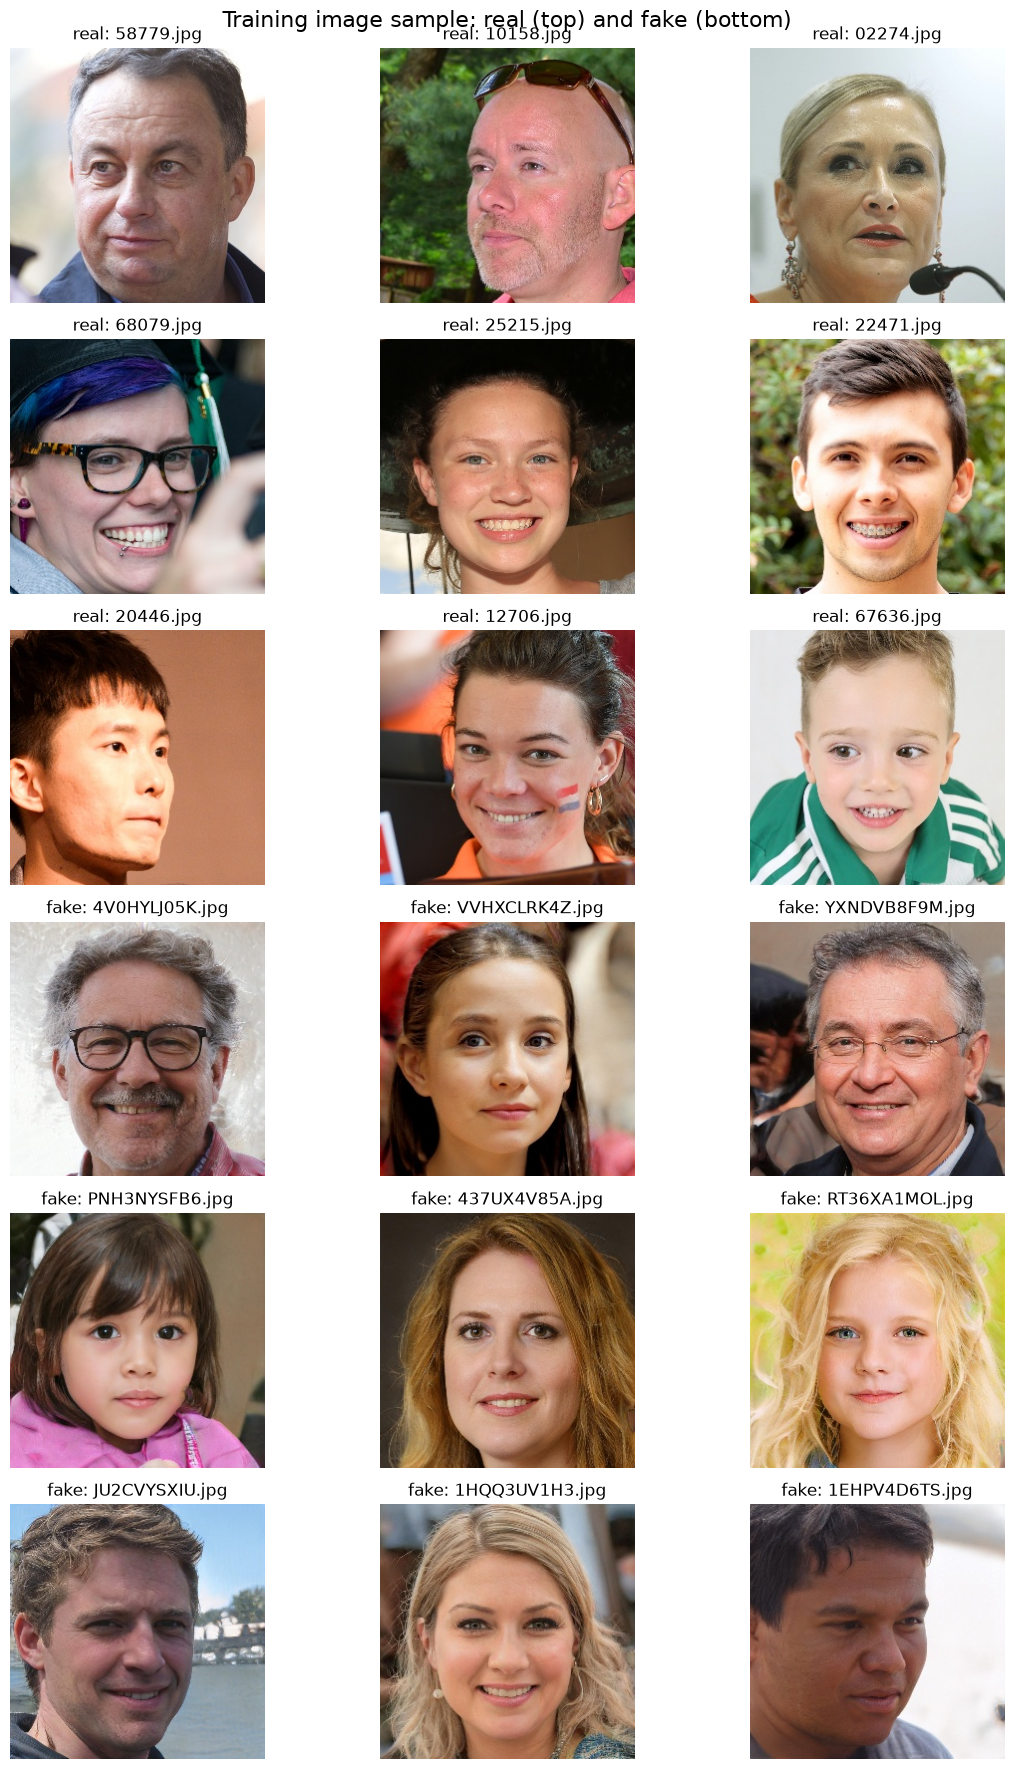

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 3, figsize=(12, 18))
grid_rng = random.Random(SEED)
for row, class_name in enumerate(CLASSES):
    selected = grid_rng.sample(IMAGE_PATHS["train"][class_name], 9)
    for offset, path in enumerate(selected):
        axis = axes[row * 3 + offset // 3, offset % 3]
        with Image.open(path) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(f"{class_name}: {path.name}")
        axis.axis("off")
fig.suptitle("Training image sample: real (top) and fake (bottom)", fontsize=16)
fig.tight_layout()
plt.show()

Calculate RGB channel mean and standard deviation from 5,000 seeded training images and compare with ImageNet.

In [8]:
import numpy as np

train_paths = [path for class_name in CLASSES for path in IMAGE_PATHS["train"][class_name]]
stats_sample = random.Random(SEED).sample(train_paths, min(5000, len(train_paths)))
channel_sum = np.zeros(3, dtype=np.float64)
channel_squared_sum = np.zeros(3, dtype=np.float64)
pixel_count = 0
for path in stats_sample:
    with Image.open(path) as image:
        pixels = np.asarray(image.convert("RGB"), dtype=np.float64) / 255.0
    channel_sum += pixels.sum(axis=(0, 1))
    channel_squared_sum += np.square(pixels).sum(axis=(0, 1))
    pixel_count += pixels.shape[0] * pixels.shape[1]
channel_mean = channel_sum / pixel_count
channel_std = np.sqrt(channel_squared_sum / pixel_count - np.square(channel_mean))
imagenet_mean = np.array([0.485, 0.456, 0.406])
imagenet_std = np.array([0.229, 0.224, 0.225])
print(f"Images sampled: {len(stats_sample)}")
print("RGB mean     dataset:", np.round(channel_mean, 6), " ImageNet:", imagenet_mean)
print("RGB std      dataset:", np.round(channel_std, 6), " ImageNet:", imagenet_std)

Images sampled: 5000
RGB mean     dataset: [0.521774 0.426614 0.381816]  ImageNet: [0.485 0.456 0.406]
RGB std      dataset: [0.278687 0.253004 0.254095]  ImageNet: [0.229 0.224 0.225]


Write absolute-path full manifests and deterministic stratified training/validation/test subsets, then report class counts.

In [9]:
from sklearn.model_selection import train_test_split

CSV_DIR = PROJECT_ROOT / "data" / "faces"
CSV_DIR.mkdir(parents=True, exist_ok=True)
full_manifests = {}
for split in SPLITS:
    rows = [
        {"path": str(path.resolve()), "label": 1 if class_name == "real" else 0}
        for class_name in CLASSES
        for path in IMAGE_PATHS[split][class_name]
    ]
    full_manifests[split] = pd.DataFrame(rows, columns=["path", "label"])

csv_manifests = {}
subset_sizes = {"train": 10000, "valid": 2000, "test": 2000}
for split, manifest in full_manifests.items():
    full_path = CSV_DIR / f"{split}.csv"
    manifest.to_csv(full_path, index=False)
    csv_manifests[full_path.name] = manifest

    subset_size = subset_sizes[split]
    if len(manifest) < subset_size or manifest["label"].value_counts().min() < 2:
        raise ValueError(
            f"Cannot make stratified {subset_size}-image subset from {split}: "
            f"{manifest['label'].value_counts().to_dict()}"
        )
    subset, _ = train_test_split(
        manifest, train_size=subset_size, random_state=SEED, stratify=manifest["label"]
    )
    subset = subset.sort_values(["label", "path"], kind="stable").reset_index(drop=True)
    subset_name = f"{split}_{subset_size // 1000}k.csv"
    subset.to_csv(CSV_DIR / subset_name, index=False)
    csv_manifests[subset_name] = subset

print("CSV class counts (label 1=real, 0=fake):")
for csv_name, manifest in csv_manifests.items():
    counts = manifest["label"].value_counts().reindex([1, 0], fill_value=0)
    print(f"{csv_name}: real={int(counts.loc[1])}, fake={int(counts.loc[0])}, total={len(manifest)}")

CSV class counts (label 1=real, 0=fake):
train.csv: real=50000, fake=50000, total=100000
train_10k.csv: real=5000, fake=5000, total=10000
valid.csv: real=10000, fake=10000, total=20000
valid_2k.csv: real=1000, fake=1000, total=2000
test.csv: real=10000, fake=10000, total=20000
test_2k.csv: real=1000, fake=1000, total=2000


Load one CPU batch from train_10k.csv at 224 by 224 with ImageNet normalization.

In [10]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms

from src.datasets import CsvImageDataset

imagenet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])
train_dataset = CsvImageDataset(CSV_DIR / "train_10k.csv", transform=imagenet_transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False, num_workers=0)
batch_images, batch_labels = next(iter(train_loader))
print("image shape:", tuple(batch_images.shape))
print("image dtype:", batch_images.dtype)
print("label shape:", tuple(batch_labels.shape), "label dtype:", batch_labels.dtype)
print("normalized image min/max:", float(batch_images.min()), float(batch_images.max()))

image shape: (32, 3, 224, 224)
image dtype: torch.float32
label shape: (32,) label dtype: torch.int64
normalized image min/max: -2.1179039478302 2.640000104904175
